# wav2vec2 Layerwise Analysis — Normal vs Dysarthric Speech

This notebook probes every internal layer of a pretrained **wav2vec2-base** model
to understand *where* in the transformer the acoustic properties of dysarthric speech
become linearly separable.

| Section | Content |
|---|---|
| 1 | Imports & setup |
| 2 | Load wav2vec2 model |
| 3 | Extract all-layer features (with disk cache) |
| 4 | Layerwise linear SVM probe |
| 5 | Accuracy vs layer depth plot |
| 6 | Comparison with MFCC baseline |
| 7 | t-SNE visualisation of selected layers |
| 8 | Observations |


## 1.  Imports & Setup

In [11]:
import os, numpy as np, matplotlib.pyplot as plt
import librosa, torch
from transformers import Wav2Vec2FeatureExtractor, Wav2Vec2Model
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, classification_report
from sklearn.manifold import TSNE
from tqdm.notebook import tqdm

plt.rcParams.update({"figure.dpi": 120})
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {DEVICE}")

Using device: cuda


## 2.  Load wav2vec2 Model

`facebook/wav2vec2-base-960h` was pretrained on 960 h of LibriSpeech.

**Architecture recap:**

| Component | What it does | Output dim |
|---|---|---:|
| CNN feature encoder (7 layers) | raw waveform → local acoustic frames at ~20 ms stride | 512 |
| Linear projection | projects CNN output into transformer space | 768 |
| Transformer (12 layers) | contextualises frames via self-attention | 768 |

Setting `output_hidden_states=True` gives us the projected CNN output
+ all 12 transformer layer outputs = **13 hidden states** in total.
We mean-pool each over time → one 768-dim vector per utterance per layer.


In [12]:
feature_extractor = Wav2Vec2FeatureExtractor.from_pretrained("facebook/wav2vec2-base")
model = Wav2Vec2Model.from_pretrained("facebook/wav2vec2-base")
model = model.to(DEVICE)
model.eval()
print("Model loaded.")
print(f"Number of transformer layers: {model.config.num_hidden_layers}")
print(f"Hidden size: {model.config.hidden_size}")


C:\Users\varun\AppData\Roaming\Python\Python312\site-packages\transformers\configuration_utils.py:335: UserWarning: Passing `gradient_checkpointing` to a config initialization is deprecated and will be removed in v5 Transformers. Using `model.gradient_checkpointing_enable()` instead, or if you are using the `Trainer` API, pass `gradient_checkpointing=True` in your `TrainingArguments`.
  warnings.warn(


Model loaded.
Number of transformer layers: 12
Hidden size: 768


## 3.  Extract All-Layer Features

For each wav file we:
1. Load at 16 kHz
2. Pass through the feature extractor (normalisation)
3. Run the model with `output_hidden_states=True`
4. For each of the 13 hidden states, mean-pool over the time axis → 768-dim vector

Result: one **(N, 13, 768)** tensor stored on disk as `wav2vec_features.npz`
so this cell only runs once — subsequent runs load from cache.


In [ ]:
DATA_ROOT = os.path.join("Dataset", "torgo_data")
FOLDERS   = {
    "dysarthria_male":     1,
    "dysarthria_female":   1,
    "non_dysarthria_male": 0,
    "non_dysarthria_female": 0,
}
CACHE = "cache_files/wav2vec_features.npz"
SR    = 16_000

os.makedirs("cache_files", exist_ok=True)
if os.path.exists(CACHE):
    print("Loading features from cache...")
    data        = np.load(CACHE, allow_pickle=True)
    all_hidden  = data["all_hidden"]           # (N, 13, 768)
    y_all       = data["labels"]                # (N,)
    speaker_ids = data["speaker_ids"].tolist()  # (N,)
    print(f"Loaded: {all_hidden.shape[0]} samples, "
          f"{all_hidden.shape[1]} layers, {all_hidden.shape[2]} dims")
    print(f"Speakers: {sorted(set(speaker_ids))}")
else:
    print("Extracting features — running on", DEVICE)
    all_hidden, labels, speaker_ids = [], [], []

    for folder, label in FOLDERS.items():
        folder_path = os.path.join(DATA_ROOT, folder)
        wav_files   = sorted(f for f in os.listdir(folder_path)
                             if f.endswith(".wav"))
        for fname in tqdm(wav_files, desc=folder, leave=False):
            fpath = os.path.join(folder_path, fname)
            # speaker ID = prefix before first underscore, e.g. M01, FC01
            speaker = fname.split("_")[0]
            try:
                y, _ = librosa.load(fpath, sr=SR, mono=True)
                inputs = feature_extractor(
                    y, sampling_rate=SR, return_tensors="pt"
                ).input_values.to(DEVICE)
                with torch.no_grad():
                    outputs = model(inputs, output_hidden_states=True)
                layer_vecs = np.stack([
                    h.squeeze(0).mean(dim=0).cpu().numpy()
                    for h in outputs.hidden_states
                ])  # (13, 768)
                all_hidden.append(layer_vecs)
                labels.append(label)
                speaker_ids.append(speaker)
            except Exception as e:
                print(f"Skipped {fname}: {e}")

    all_hidden = np.array(all_hidden)   # (N, 13, 768)
    y_all      = np.array(labels)
    np.savez(CACHE,
             all_hidden=all_hidden,
             labels=y_all,
             speaker_ids=np.array(speaker_ids, dtype=object))
    print(f"Saved to {CACHE}  |  shape: {all_hidden.shape}")
    print(f"Speakers: {sorted(set(speaker_ids))}")
    print(f"Normal: {(y_all==0).sum()}  Dysarthric: {(y_all==1).sum()}")

Loading features from cache...
Loaded: 1995 samples, 13 layers, 768 dims
Speakers: ['F01', 'F03', 'F04', 'FC01', 'FC02', 'FC03', 'M01', 'M02', 'M03', 'M04', 'M05', 'MC01', 'MC02', 'MC03', 'MC04']


### 3b.  Feature Preview

A quick look at what the extracted vectors look like — one row per sample, showing the mean-pooled 768-dim vector from **layer 12** (the last transformer layer).


In [ ]:
import pandas as pd
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", "{:.3f}".format)

last_layer = all_hidden[:, -1, :]             # (N, 768) — layer 12
df_preview = pd.DataFrame(
    last_layer[:5],
    columns=[f"dim_{i}" for i in range(last_layer.shape[1])]
)
df_preview["label"] = ["dysarthric" if l == 1 else "normal" for l in y_all[:5]]
print("Layer 12 (last transformer layer) — first 5 samples, first 20 dims:")
display(df_preview.iloc[:, :21])
print(f"\nFull feature matrix per layer: {all_hidden[:, 0, :].shape}")

Layer 12 (last transformer layer) — first 5 samples, first 20 dims:


,dim_0,dim_1,dim_2,dim_3,dim_4,dim_5,dim_6,dim_7,dim_8,dim_9,...,dim_11,dim_12,dim_13,dim_14,dim_15,dim_16,dim_17,dim_18,dim_19,dim_20
0,-0.088,-0.030,0.143,0.060,0.197,0.066,0.205,-0.038,-0.062,0.013,...,0.136,-0.112,0.188,0.129,0.137,0.104,0.025,-0.085,-0.267,-0.314
1,-0.048,-0.024,0.135,0.046,0.192,0.096,0.187,-0.022,-0.057,0.082,...,0.126,0.017,0.232,0.183,0.208,-0.039,0.039,-0.087,-0.180,-0.256
2,-0.092,-0.029,0.174,0.036,0.159,0.054,0.224,-0.016,-0.025,0.053,...,0.190,-0.062,0.293,0.261,0.152,-0.007,-0.014,-0.111,-0.295,-0.224
3,-0.055,-0.046,0.106,-0.003,0.268,0.162,0.213,0.054,0.076,0.035,...,0.101,-0.049,0.255,0.250,0.170,0.021,-0.072,-0.080,-0.314,-0.239
4,-0.112,-0.006,0.091,-0.001,0.226,0.100,0.278,0.011,0.012,0.057,...,0.184,-0.045,0.310,0.216,0.099,-0.014,-0.042,-0.126,-0.415,-0.223



Full feature matrix per layer: (1995, 768)


## 4.  Layerwise Linear SVM Probe

For each of the 13 layers we:
1. Take the (N, 768) mean-pooled features
2. Run 5-fold CV with a **linear SVM** (Pipeline with StandardScaler)

**Why linear SVM (not RBF)?**
Linear probing is the standard methodology in representation analysis.
If a *linear* probe achieves high accuracy, the layer has learned a representation
where dysarthric and normal speech are *linearly separable* in 768-D space.
Using RBF would mix "quality of representation" with "non-linearity of the classifier",
making it harder to attribute accuracy changes to the model.


In [15]:
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

LAYER_NAMES  = ["CNN"] + [f"Transformer L{i}" for i in range(1, 13)]
speaker_arr  = np.array(speaker_ids)
loso         = LeaveOneGroupOut()

unique_speakers = sorted(set(speaker_ids))
print(f"Speakers ({len(unique_speakers)}): {unique_speakers}")
print(f"LOSO folds: {loso.get_n_splits(groups=speaker_arr)}\n")

layer_results = []

for layer_idx in range(all_hidden.shape[1]):
    X = all_hidden[:, layer_idx, :]   # (N, 768)

    fold_accs = []
    all_true, all_pred = [], []
    for tr_idx, te_idx in loso.split(X, y_all, groups=speaker_arr):
        pipe = Pipeline([
            ("scaler", StandardScaler()),
            ("svm",    LinearSVC(max_iter=3000, random_state=42)),
        ])
        pipe.fit(X[tr_idx], y_all[tr_idx])
        preds = pipe.predict(X[te_idx])
        fold_accs.append(accuracy_score(y_all[te_idx], preds))
        all_true.extend(y_all[te_idx].tolist())
        all_pred.extend(preds.tolist())

    fold_accs = np.array(fold_accs)
    layer_results.append({
        "layer":     LAYER_NAMES[layer_idx],
        "cv_mean":   fold_accs.mean(),
        "cv_std":    fold_accs.std(),
        "fold_accs": fold_accs,
        "all_true":  all_true,
        "all_pred":  all_pred,
    })
    print(f"  {LAYER_NAMES[layer_idx]:20s}  "
          f"LOSO mean={fold_accs.mean():.3f}  std={fold_accs.std():.3f}  "
          f"min={fold_accs.min():.3f}  max={fold_accs.max():.3f}")

best_layer_idx = max(range(len(layer_results)), key=lambda i: layer_results[i]["cv_mean"])
print(f"\nBest layer: {LAYER_NAMES[best_layer_idx]} "
      f"(LOSO mean={layer_results[best_layer_idx]['cv_mean']:.3f})")
print(f"\nClassification Report — {LAYER_NAMES[best_layer_idx]} (all LOSO folds):")
print(classification_report(
    layer_results[best_layer_idx]["all_true"],
    layer_results[best_layer_idx]["all_pred"],
    target_names=["Normal", "Dysarthric"]
))


Speakers (15): ['F01', 'F03', 'F04', 'FC01', 'FC02', 'FC03', 'M01', 'M02', 'M03', 'M04', 'M05', 'MC01', 'MC02', 'MC03', 'MC04']
LOSO folds: 15

  CNN                   LOSO mean=0.659  std=0.322  min=0.065  max=1.000
  Transformer L1        LOSO mean=0.737  std=0.293  min=0.146  max=0.987
  Transformer L2        LOSO mean=0.685  std=0.313  min=0.073  max=0.987
  Transformer L3        LOSO mean=0.721  std=0.294  min=0.031  max=0.973
  Transformer L4        LOSO mean=0.716  std=0.284  min=0.073  max=0.991
  Transformer L5        LOSO mean=0.720  std=0.256  min=0.177  max=0.989
  Transformer L6        LOSO mean=0.765  std=0.225  min=0.274  max=0.991
  Transformer L7        LOSO mean=0.755  std=0.209  min=0.250  max=0.981
  Transformer L8        LOSO mean=0.800  std=0.186  min=0.394  max=0.987
  Transformer L9        LOSO mean=0.741  std=0.243  min=0.260  max=0.991
  Transformer L10       LOSO mean=0.732  std=0.257  min=0.229  max=1.000
  Transformer L11       LOSO mean=0.727  std=0.255  m

## 5.  Accuracy vs Layer Depth

The key plot: how does probing accuracy change as we go deeper into the model?

- **CNN layer (index 0)**: purely local acoustic features, no context
- **Early transformer layers (1-4)**: low-level phonetic patterns
- **Middle layers (5-8)**: phoneme identity, coarticulation
- **Late layers (9-12)**: high-level linguistic / speaker-level features

For dysarthria (a motor speech disorder), we expect the most discriminative
signal to emerge in mid-to-late layers where articulation patterns are encoded.


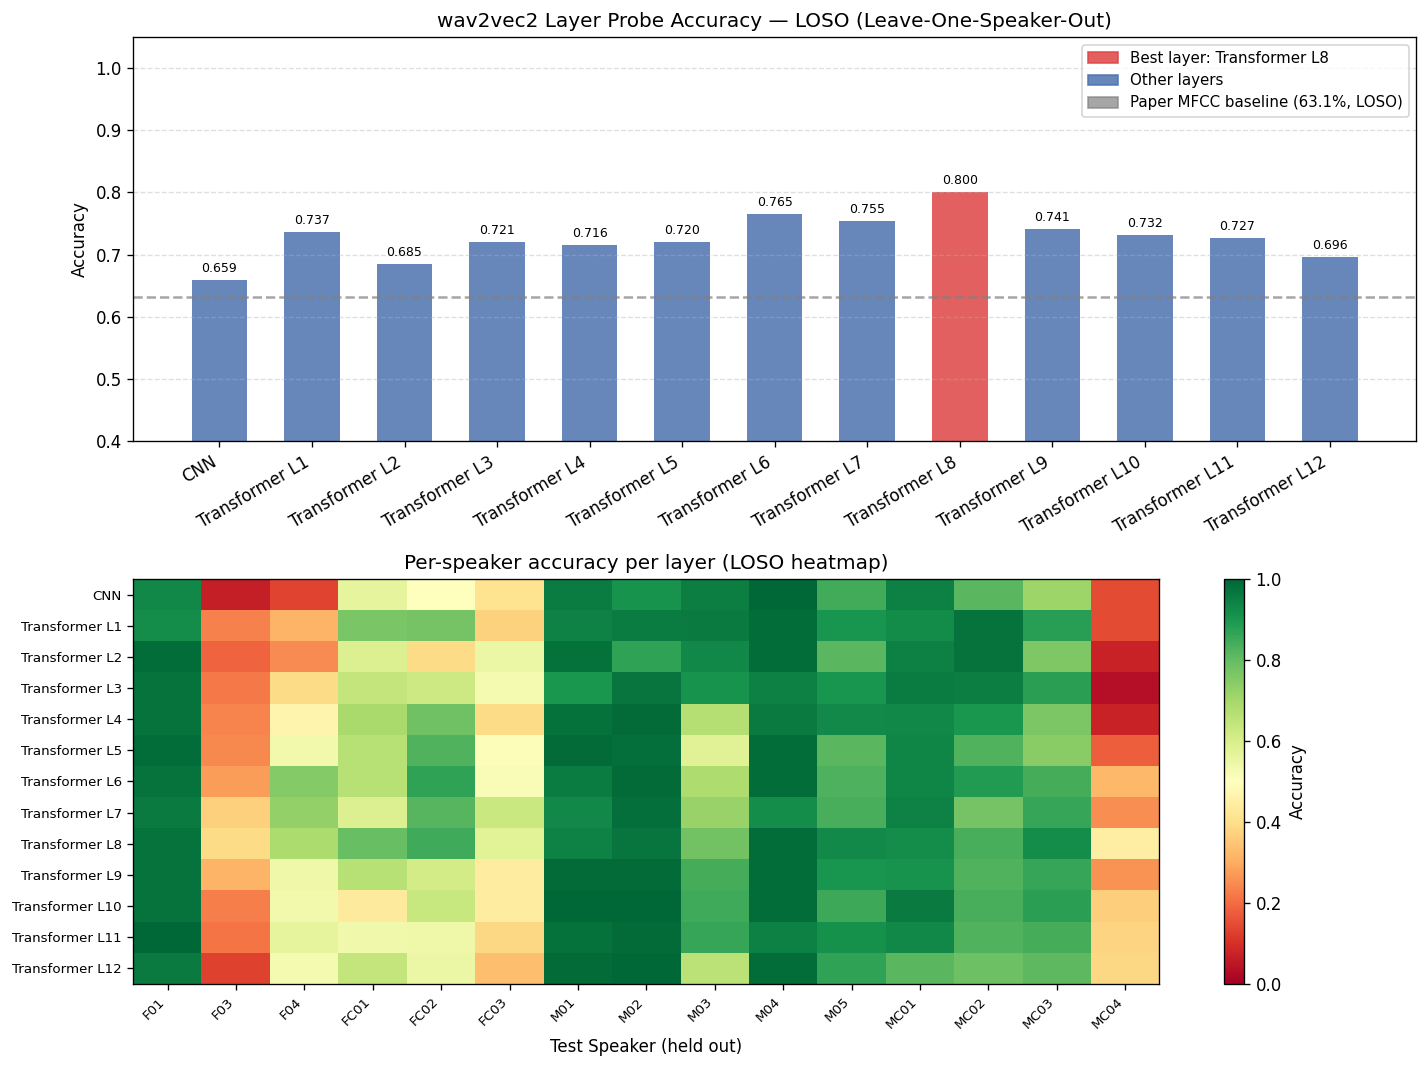

In [ ]:
from matplotlib.patches import Patch

cv_means = [r["cv_mean"] for r in layer_results]
cv_stds  = [r["cv_std"]  for r in layer_results]
x        = np.arange(len(LAYER_NAMES))

fig, axes = plt.subplots(2, 1, figsize=(12, 9))

# bar chart
ax = axes[0]
colors = ["#DD4444" if i == best_layer_idx else "#4C72B0" for i in x]
bars = ax.bar(x, cv_means, color=colors, alpha=0.85, width=0.6)
ax.bar_label(bars, fmt="{:.3f}", padding=3, fontsize=7.5)
ax.axhline(0.6313, color="grey", linestyle="--", alpha=0.7)
ax.set_xticks(x)
ax.set_xticklabels(LAYER_NAMES, rotation=30, ha="right")
ax.set_ylabel("Accuracy")
ax.set_title("wav2vec2 Layer Probe Accuracy — LOSO (Leave-One-Speaker-Out)")
ax.set_ylim(0.4, 1.05)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.legend(handles=[
    Patch(color="#DD4444", alpha=0.85, label=f"Best layer: {LAYER_NAMES[best_layer_idx]}"),
    Patch(color="#4C72B0", alpha=0.85, label="Other layers"),
    Patch(color="grey",    alpha=0.7,  label="Paper MFCC baseline (63.1%, LOSO)"),
], fontsize=9)

# per speaker heatmap
ax2 = axes[1]
heatmap = np.array([r["fold_accs"] for r in layer_results])  # (13, n_speakers)
im = ax2.imshow(heatmap, aspect="auto", cmap="RdYlGn",
                vmin=0.0, vmax=1.0, origin="upper")
ax2.set_yticks(x)
ax2.set_yticklabels(LAYER_NAMES, fontsize=8)
ax2.set_xticks(range(len(unique_speakers)))
ax2.set_xticklabels(unique_speakers, rotation=45, ha="right", fontsize=8)
ax2.set_xlabel("Test Speaker (held out)")
ax2.set_title("Per-speaker accuracy per layer (LOSO heatmap)")
plt.colorbar(im, ax=ax2, label="Accuracy")

plt.tight_layout()
plt.show()

### 4b.  Confusion Matrix — Best Layer

Aggregated across all LOSO folds (% of total samples).


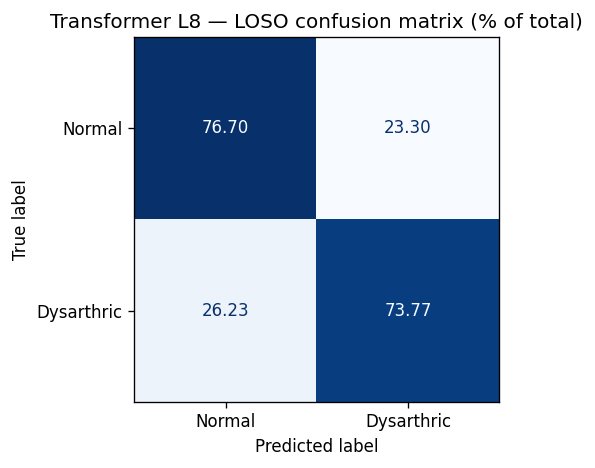

In [17]:
best = layer_results[best_layer_idx]
cm = confusion_matrix(best["all_true"], best["all_pred"], normalize="true")
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(cm * 100, display_labels=["Normal", "Dysarthric"]).plot(
    ax=ax, colorbar=False, cmap="Blues", values_format=".2f"
)
ax.set_title(f"{LAYER_NAMES[best_layer_idx]} — LOSO confusion matrix (% of total)")
plt.tight_layout()
plt.show()


## 6.  Comparison with MFCC Baseline

We now compare the best wav2vec2 layer against the MFCC-based classifiers
from the previous notebook. Enter your MFCC results below after running that notebook.


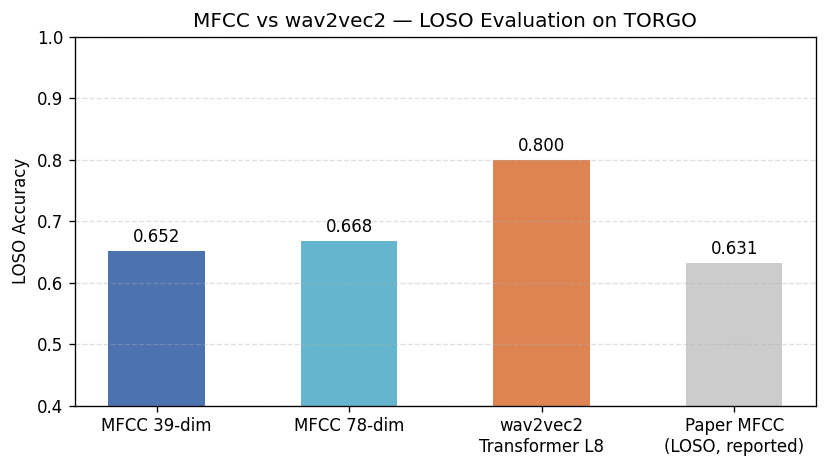

In [ ]:
MFCC_39_LOSO = 0.652 
MFCC_78_LOSO = 0.668   
best_w2v = layer_results[best_layer_idx]["cv_mean"]

methods = [
    "MFCC 39-dim",
    "MFCC 78-dim",
    f"wav2vec2\n{LAYER_NAMES[best_layer_idx]}",
    "Paper MFCC\n(LOSO, reported)",
]
values  = [MFCC_39_LOSO, MFCC_78_LOSO, best_w2v, 0.6313]
colours = ["#4C72B0", "#64B5CD", "#DD8452", "#cccccc"]

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(methods, values, color=colours, width=0.5)
ax.bar_label(bars, fmt="{:.3f}", padding=3)
ax.set_ylabel("LOSO Accuracy")
ax.set_title("MFCC vs wav2vec2 — LOSO Evaluation on TORGO")
ax.set_ylim(0.4, 1.0)
ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()
